# Data exploration of the dataset

### Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Defining the variables according to what type they are

In [60]:
categorical_vars = ["pneum", "asthma", "irondef", "hemo", "gender",
                    "malnutrition", "fibrosisandother", "depress",
                    "psychother", "psychologicaldisordermajor",
                    "substancedependence", "dialysisrenalendstage"]
comorbidities_vars = ["pneum", "asthma", "irondef", "hemo",
                    "malnutrition", "fibrosisandother", "depress",
                    "psychother", "psychologicaldisordermajor",
                    "substancedependence", "dialysisrenalendstage"]
continuous_vars = ["hematocrit", "neutrophils", "sodium", "glucose",
                  "bloodureanitro", "creatinine", "bmi", "pulse",
                  "respiration" ]

Loading the dataset in a pandas DataFrame

In [3]:
df = pd.read_csv("data/LengthOfStay.csv")
df.head()

,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,1,8/29/2012,0,F,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,9/1/2012,B,3
1,2,5/26/2012,5+,F,0,0,0,0,0,0,...,94.078507,8.0,0.943164,28.460516,61,6.5,1,6/2/2012,A,7
2,3,9/22/2012,1,F,0,0,0,0,0,0,...,130.530524,12.0,1.065750,28.843812,64,6.5,2,9/25/2012,B,3
3,4,8/9/2012,0,F,0,0,0,0,0,0,...,163.377028,12.0,0.906862,27.959007,76,6.5,1,8/10/2012,A,1
4,5,12/20/2012,0,F,0,0,0,1,0,1,...,94.886654,11.5,1.242854,30.258927,67,5.6,2,12/24/2012,E,4


Readmission count means how many times was the patient present at the hospital in a 180-day window.

In [4]:
df["rcount"].unique()

<StringArray>
['0', '5+', '1', '3', '4', '2']
Length: 6, dtype: str

### Exploration

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   eid                         100000 non-null  int64  
 1   vdate                       100000 non-null  str    
 2   rcount                      100000 non-null  str    
 3   gender                      100000 non-null  str    
 4   dialysisrenalendstage       100000 non-null  int64  
 5   asthma                      100000 non-null  int64  
 6   irondef                     100000 non-null  int64  
 7   pneum                       100000 non-null  int64  
 8   substancedependence         100000 non-null  int64  
 9   psychologicaldisordermajor  100000 non-null  int64  
 10  depress                     100000 non-null  int64  
 11  psychother                  100000 non-null  int64  
 12  fibrosisandother            100000 non-null  int64  
 13  malnutrition              

In [6]:
df.describe()

,eid,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,fibrosisandother,...,neutrophils,sodium,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,lengthofstay
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000
mean,50000.500000,0.036420,0.035270,0.094940,0.039450,0.063060,0.239040,0.051660,0.049390,0.004790,...,10.177455,137.891397,141.963384,14.097185,1.099350,29.805759,73.444720,6.493768,2.123310,4.00103
std,28867.657797,0.187334,0.184462,0.293134,0.194664,0.243072,0.426499,0.221341,0.216682,0.069044,...,5.353131,2.999669,29.992996,12.952454,0.200262,2.003769,11.644555,0.568473,2.050641,2.36031
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.100000,124.912632,-1.005927,1.000000,0.219770,21.992683,21.000000,0.200000,0.000000,1.00000
25%,25000.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,7.700000,135.871062,121.682383,11.000000,0.964720,28.454235,66.000000,6.500000,1.000000,2.00000
50%,50000.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,9.400000,137.887151,142.088545,12.000000,1.098764,29.807516,73.000000,6.500000,1.000000,4.00000
75%,75000.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,11.500000,139.912885,162.180996,14.000000,1.234867,31.156885,81.000000,6.500000,3.000000,6.00000
max,100000.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,245.900000,151.387283,271.444277,682.500000,2.035202,38.935293,130.000000,10.000000,10.000000,17.00000


In [7]:
df.isnull().sum()

eid                           0
vdate                         0
rcount                        0
gender                        0
dialysisrenalendstage         0
asthma                        0
irondef                       0
pneum                         0
substancedependence           0
psychologicaldisordermajor    0
depress                       0
psychother                    0
fibrosisandother              0
malnutrition                  0
hemo                          0
hematocrit                    0
neutrophils                   0
sodium                        0
glucose                       0
bloodureanitro                0
creatinine                    0
bmi                           0
pulse                         0
respiration                   0
secondarydiagnosisnonicd9     0
discharged                    0
facid                         0
lengthofstay                  0
dtype: int64

Variable cible : `lengthofstay`

<Axes: xlabel='lengthofstay', ylabel='Count'>

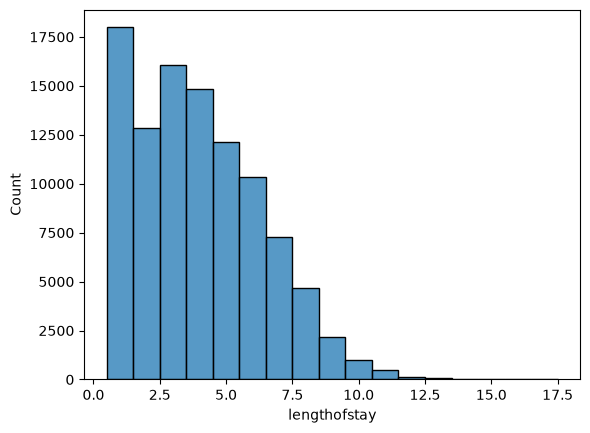

In [8]:
sns.histplot(df, x="lengthofstay",discrete=True)

Il y a une asymétrie vers la droite. Les valeurs ne suivent pas une loi normale. Ainsi, la moyenne est tirée vers la droite par
le peu de séjours qui ont été très longs (plus de 12 jours).

Sur une régression linéaire classique, l'intervalle d'incertitude sera symétrique de type $1.96\sigma_{err}$.

Le modèle finira par prédire des durées de séjour négatives pour la majorité des patients simples.

Let's check the readmission count

<Axes: xlabel='rcount', ylabel='Count'>

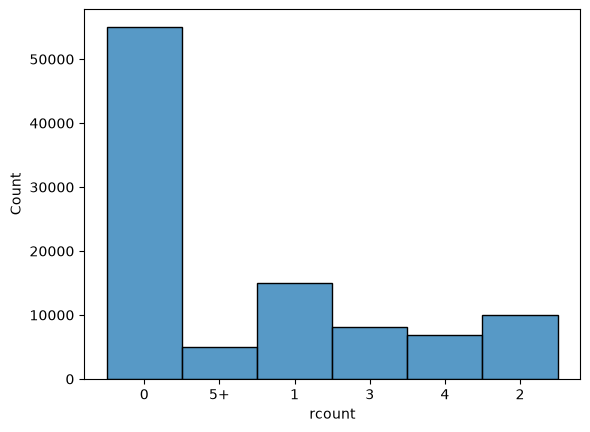

In [9]:
sns.histplot(df, x="rcount")

<Axes: xlabel='gender', ylabel='Count'>

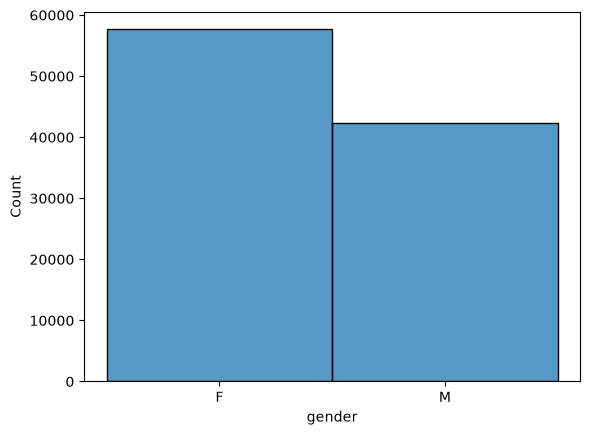

In [10]:
sns.histplot(df, x="gender")

<Axes: xlabel='irondef'>

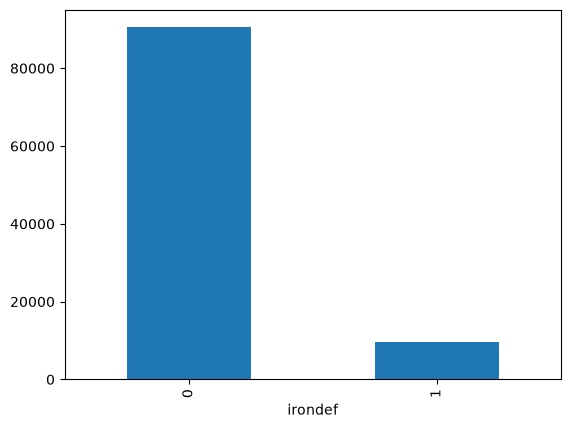

In [11]:
df['irondef'].value_counts().plot(kind='bar')

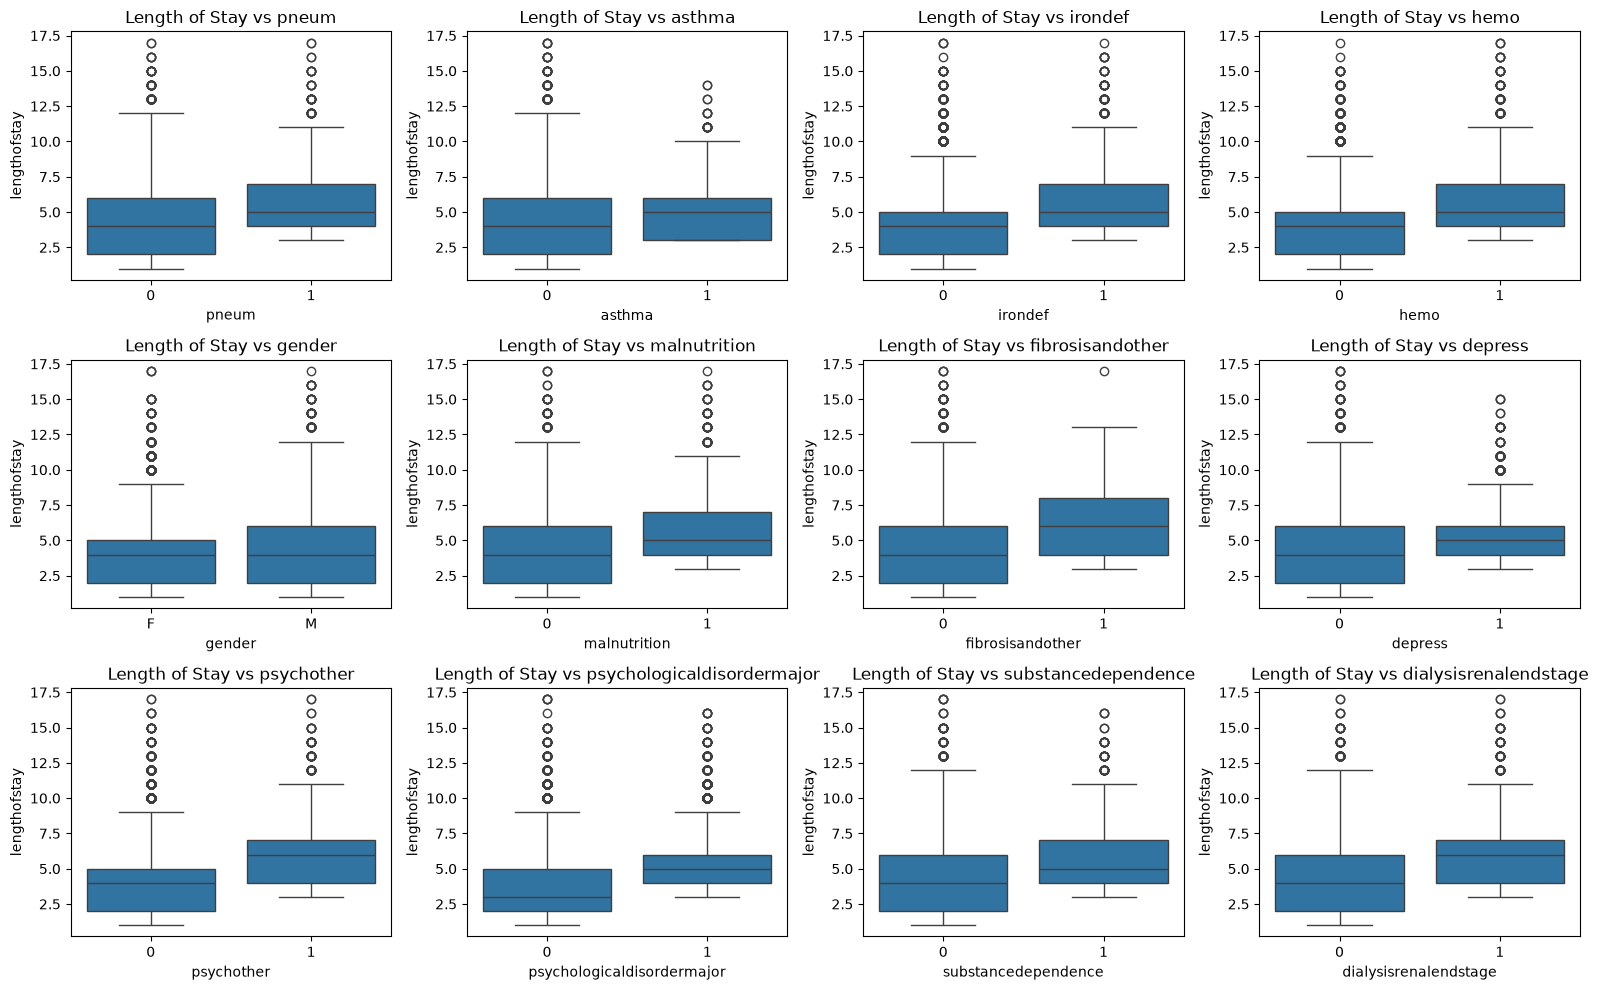

In [12]:


# Create a grid of subplots (2 rows, 3 columns)
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy looping

# Iterate through the variables and plot them on specific axes
for i, var in enumerate(categorical_vars):
    sns.boxplot(data=df, x=var, y="lengthofstay", ax=axes[i])
    axes[i].set_title(f"Length of Stay vs {var}")

plt.tight_layout()
plt.show()

On voit qu'avoir un problème lorsqu'on est admis augmente le temps passé à l'hôpital dans la plupart des cas. Uniquement `gender` n'evoque pas de predisposition a un temps plus ou moins long passe a l'hopital.

Hexbins for numerical variables

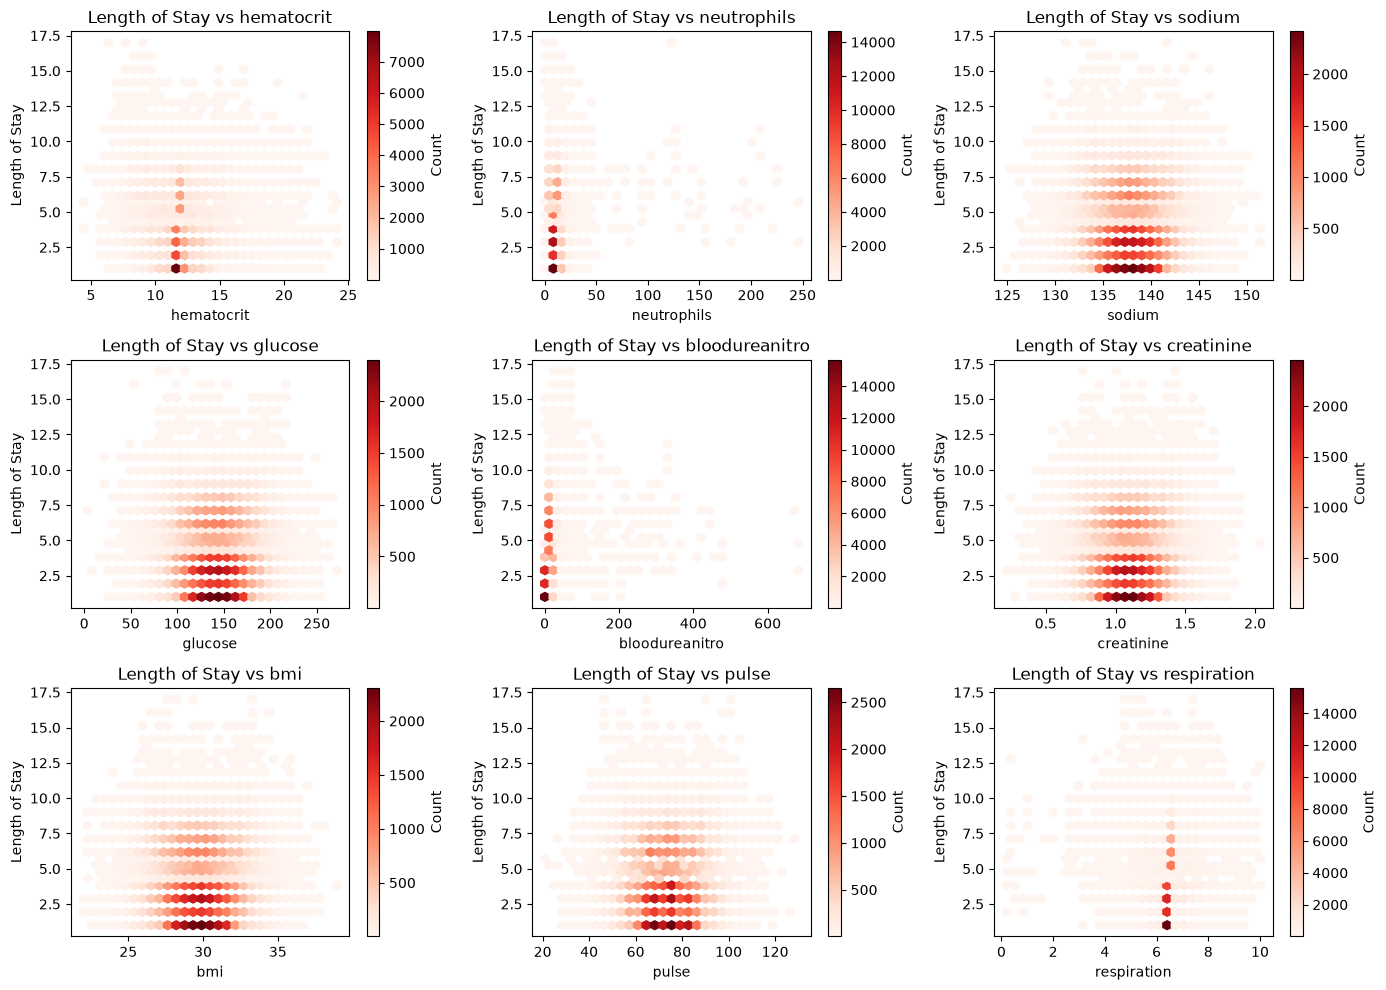

In [34]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(14, 10))
axes = axes.flatten()

for i, var in enumerate(continuous_vars):
    hb = axes[i].hexbin(df[var], df["lengthofstay"], gridsize=30, cmap='Reds', mincnt=1)
    axes[i].set_title(f"Length of Stay vs {var}")
    axes[i].set_xlabel(var)
    axes[i].set_ylabel("Length of Stay")
    fig.colorbar(hb, ax=axes[i], label='Count')

plt.tight_layout()
plt.show()

On remarque qu'en fonction de l'évolution de la valeur des différentes moyennes, le patient ne reste pas le même temps à l'hôpital. La variance n'est pas constance et les données sont asymétriques, ici une régression linéaire ne serait pas très efficace.

#### Correlation matrix

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   eid                         100000 non-null  int64  
 1   vdate                       100000 non-null  str    
 2   rcount                      100000 non-null  str    
 3   gender                      100000 non-null  str    
 4   dialysisrenalendstage       100000 non-null  int64  
 5   asthma                      100000 non-null  int64  
 6   irondef                     100000 non-null  int64  
 7   pneum                       100000 non-null  int64  
 8   substancedependence         100000 non-null  int64  
 9   psychologicaldisordermajor  100000 non-null  int64  
 10  depress                     100000 non-null  int64  
 11  psychother                  100000 non-null  int64  
 12  fibrosisandother            100000 non-null  int64  
 13  malnutrition              

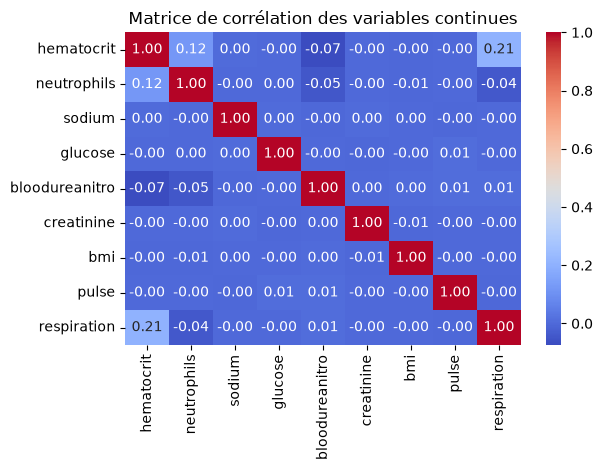

In [ ]:
sns.heatmap(df[continuous_vars].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Matrice de corrélation des variables continues")
plt.tight_layout()
plt.show()

Aucune colonne numérique ne corrèle avec une autre, il est intéressant ici de les garder toutes. 

### Feature engineering

Let's create a new variable `monthofstay` from the date of admission to see if there is a season related correlation with the `lengthofstay`

In [35]:
df["vdate"].head()

0     8/29/2012
1     5/26/2012
2     9/22/2012
3      8/9/2012
4    12/20/2012
Name: vdate, dtype: str

In [36]:
df["monthofstay"] = pd.DatetimeIndex(df["vdate"]).month
df["monthofstay"].head()

0     8
1     5
2     9
3     8
4    12
Name: monthofstay, dtype: int32

Let's see if the month have an influence over the length of stay in the hospital

<Axes: xlabel='monthofstay'>

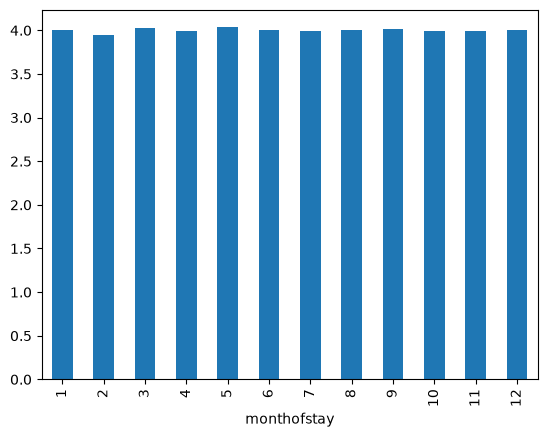

In [37]:
df.groupby(["monthofstay"])["lengthofstay"].mean().plot(kind="bar")

There is no seasonality in the length of stay based on the month the patient was admitted in the hospital.

The `monthofstay` column is not that relevant. And the `vdate` is not necessarily to be kept.

In [40]:
df = df.drop(["monthofstay"], axis=1)

In [41]:
df.head()

,eid,vdate,rcount,gender,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,discharged,facid,lengthofstay
0,1,8/29/2012,0,F,0,0,0,0,0,0,...,192.476918,12.0,1.390722,30.432418,96,6.5,4,9/1/2012,B,3
1,2,5/26/2012,5+,F,0,0,0,0,0,0,...,94.078507,8.0,0.943164,28.460516,61,6.5,1,6/2/2012,A,7
2,3,9/22/2012,1,F,0,0,0,0,0,0,...,130.530524,12.0,1.065750,28.843812,64,6.5,2,9/25/2012,B,3
3,4,8/9/2012,0,F,0,0,0,0,0,0,...,163.377028,12.0,0.906862,27.959007,76,6.5,1,8/10/2012,A,1
4,5,12/20/2012,0,F,0,0,0,1,0,1,...,94.886654,11.5,1.242854,30.258927,67,5.6,2,12/24/2012,E,4


Let's compare `vdate` & `discharged` with the `lengthofstay` and see if it is really needed or not.

In [42]:
my_length_of_stay =  df["discharged"].apply(pd.to_datetime) - df["vdate"].apply(pd.to_datetime)

In [43]:
print((my_length_of_stay.dt.days == df["lengthofstay"]).sum())

100000


Littéralement tous les `lengthofstay` sont correctes, on peut donc se séparer de la colonne `discharged` qui introduirait de la fuite de données pour l'entraînement du modèle.

In [ ]:
df = df.drop(["discharged"],  axis=1)

KeyError: "['discharged'] not found in axis"

De plus, on a la colonne `eid` qui ne sert à rien pour notre modèle.

In [55]:
df = df.drop(["eid"], axis=1)

Nous avons vu que la colonne `gender` n'apportait pas forcément plus d'informations, et de plus, elle est une variable sur la démographie, ainsi, n'apportant pas d'informations supplémentaires, il est également important de la supprimer. Cela permet de se prémunir contre l'introduction de biais.

In [56]:
df = df.drop(["gender"], axis=1)

In [48]:
df["facid"].unique()

<StringArray>
['B', 'A', 'E', 'D', 'C']
Length: 5, dtype: str

Pour finir, ce qui est intéressant, c'est de construire une nouvelle colonne `comorbidities` qui contiendra le nombre de comorbidités qu'un patient a. Par exemple, si le patient est dépressif et a une pneunomie, son score de comorbitié sera 2.

In [70]:
df["comorbidities"] = df[comorbidities_vars].sum(axis=1)

In [71]:
df["comorbidities"].describe()

count    100000.000000
mean          0.743500
std           1.097406
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max           9.000000
Name: comorbidities, dtype: float64

In [69]:
df[df["comorbidities"] == 9]

,vdate,rcount,dialysisrenalendstage,asthma,irondef,pneum,substancedependence,psychologicaldisordermajor,depress,psychother,...,glucose,bloodureanitro,creatinine,bmi,pulse,respiration,secondarydiagnosisnonicd9,facid,lengthofstay,comorbidities
88238,4/29/2012,0,1,1,1,1,1,1,0,1,...,140.511398,49.0,1.251143,27.655853,89,6.4,0,E,8,9
93238,9/6/2012,0,1,1,1,1,1,1,0,1,...,103.760975,49.0,1.127242,32.319676,78,6.4,1,E,8,9
98238,9/27/2012,4,1,1,1,1,1,1,0,1,...,197.509422,49.0,1.652982,30.632861,82,6.4,9,E,12,9


On voit quand meme qu'avec 9 comorbidités, un.e patient.e aura tendance à rester beaucoup plus longtemps à l'hôpital.